In [1]:
### Imports and Libraries

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import pickle
from matplotlib.lines import Line2D
from matplotlib.colors import LinearSegmentedColormap, ListedColormap
from matplotlib.patches import Patch
from shapely.geometry import Point
from geopandas import GeoDataFrame
from ipywidgets import interact, FloatSlider

# Load the trained 3-variable GP outputs (single pickle dictionary).
# This notebook lives in "model visualizations/"; project files are one level up.
with open('../model outputs/gp_model_Upper.pkl', 'rb') as f:
    gp_output = pickle.load(f)

section_name = gp_output['section_name']
gp_model_3v = gp_output['gp_model_3v']
scaler_X_3v = gp_output['scaler_X_3v']
scaler_y_3v = gp_output['scaler_y_3v']
X_3v = gp_output['X_3v']
y_3v = gp_output['y_3v']
y_pred_3v = gp_output['y_pred_3v']
y_std_3v = gp_output['y_std_3v']
gp_data_3v = gp_output['gp_data_3v']
input_columns_3v = gp_output['input_columns_3v']
output_column_3v = gp_output['output_column_3v']
input_label_1_3v = gp_output['input_label_1_3v']
input_label_2_3v = gp_output['input_label_2_3v']
input_label_3_3v = gp_output['input_label_3_3v']
output_label_3v = gp_output['output_label_3v']
r2_3v = gp_output['r2_3v']
rmse_3v = gp_output['rmse_3v']
mae_3v = gp_output['mae_3v']
cv_r2_mean = gp_output['cv_r2_mean']
cv_r2_std = gp_output['cv_r2_std']
cv_rmse_mean = gp_output['cv_rmse_mean']
cv_rmse_std = gp_output['cv_rmse_std']
cv_mae_mean = gp_output['cv_mae_mean']
cv_mae_std = gp_output['cv_mae_std']
output_unit_3v = gp_output['output_unit_3v']
FT_TO_M = gp_output['FT_TO_M']
reference_distance = gp_output['reference_distance']

def format_label_3v(col_name):
    """Convert column name to readable label."""
    return col_name.replace('_', ' ').title()

input_unit_1_3v = 'm'

print(f"Loaded GP outputs for section: {section_name}")
print(f"  Training points: {len(gp_data_3v)}")
print(f"  Model: {type(gp_model_3v).__name__}")
print(f"  CV R²: {cv_r2_mean:.4f} ± {cv_r2_std:.4f}")


Loaded GP outputs for section: Upper
  Training points: 287
  Model: GaussianProcessRegressor
  CV R²: -0.1581 ± 0.2038


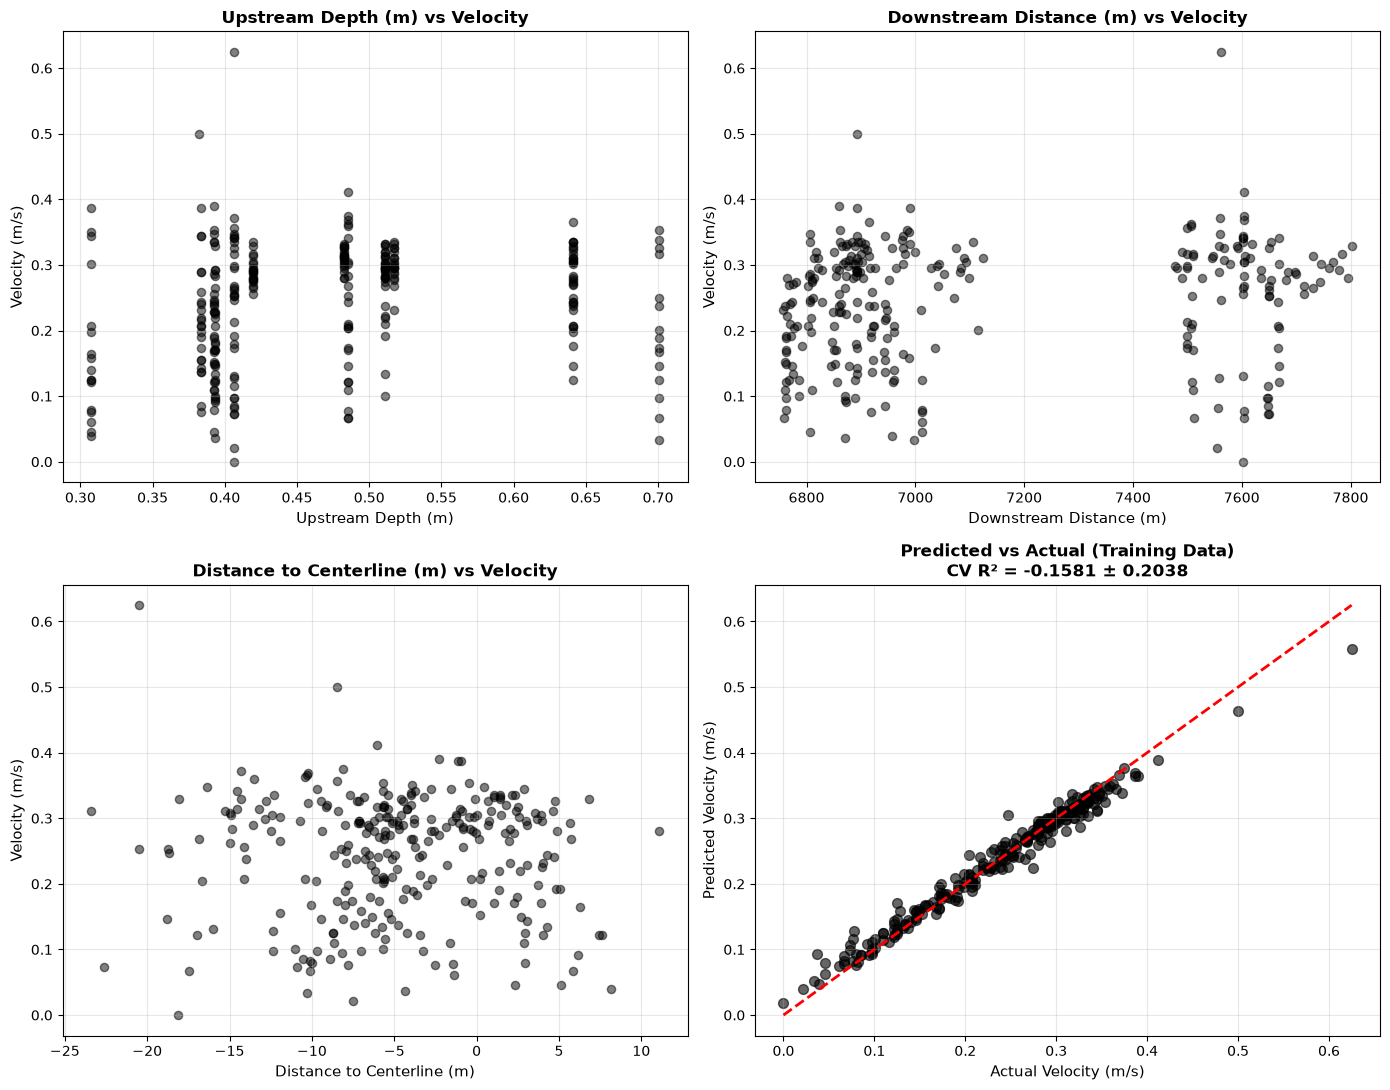


--------------------------------------------------------------------------------
Creating Interactive 2D Heatmap Visualization...
--------------------------------------------------------------------------------

✓ Interactive 2D Heatmap created successfully!
  Resolution: 50x50 grid points
  Distance To Centerline (m) range: [-23.41, 23.41] (symmetric)
  Downstream Dist (m) range: [6754.54, 7804.98]
  Actual data - Distance To Centerline (m): [-23.41, 11.08]
  Actual data - Downstream Dist (m): [6757.54, 7801.98]
  Upstream Depth slider range: [0.307, 0.701] m

Use the slider below to adjust Upstream Depth:


interactive(children=(FloatSlider(value=0.4823000154336, continuous_update=False, description='Upstream Depth:…

<function __main__.plot_velocity_heatmap(upstream_depth)>

In [2]:
### 9) 3v Model Visualizations
# Heat map and 1-to-1 plots

# 2x2 Plot: Each input vs velocity (actual and predicted) + model verification (Predicted vs Actual)
fig, axes = plt.subplots(2, 2, figsize=(14, 11))
input_labels = [
    'Upstream Depth (m)', 
    'Downstream Distance (m)', 
    'Distance to Centerline (m)'
]
input_columns = [
    'upstream_depth', 
    'downstream_dist', 
    'distance_to_centerline'
]
inputs = [gp_data_3v[col] for col in input_columns]

# Scatter: Input vs Actual velocity (colored by sensor type only)
for idx, (ax, input_data, label) in enumerate(zip(axes.flat[:3], inputs, input_labels)):
    # Plot actual values colored by data type (Sontek=blue, HRWC Sensor=brown)
    scatter = ax.scatter(input_data, y_3v, alpha=0.5, c='black', s=35)
    ax.set_xlabel(label, fontsize=11)
    ax.set_ylabel('Velocity (m/s)', fontsize=11)
    ax.set_title(f'{label} vs Velocity', fontsize=12, fontweight='bold')
    ax.grid(True, alpha=0.3)

# Scatter: Predicted vs Actual (model verification) - colored by sensor type
ax_pred = axes.flat[3]
ax_pred.scatter(y_3v, y_pred_3v, alpha=0.6, c='black', s=50)
ax_pred.plot([y_3v.min(), y_3v.max()], [y_3v.min(), y_3v.max()], 'r--', lw=2)
ax_pred.set_xlabel('Actual Velocity (m/s)', fontsize=11)
ax_pred.set_ylabel('Predicted Velocity (m/s)', fontsize=11)
ax_pred.set_title(f'Predicted vs Actual (Training Data)\nCV R² = {cv_r2_mean:.4f} ± {cv_r2_std:.4f}', fontsize=12, fontweight='bold')
ax_pred.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# =====================================================================
# 2D Heatmap: Velocity Predictions vs Spatial Position (Interactive)
# =====================================================================

print("\n" + "-"*80)
print("Creating Interactive 2D Heatmap Visualization...")
print("-"*80)

# Create a 2D heatmap showing velocity predictions as a function of
# downstream_dist (y-axis) and distance_to_centerline (x-axis)

# Get range for upstream_depth slider
upstream_depth_min = X_3v[:, 0].min()
upstream_depth_max = X_3v[:, 0].max()
upstream_depth_median = np.median(X_3v[:, 0])

# Create grid for distance_to_centerline (x-axis) and downstream_dist (y-axis)
n_points_heatmap = 50

# For distance_to_centerline, create symmetric range around 0 to show both sides of river
# Get the maximum absolute distance to ensure all data is captured
max_dist_to_centerline = max(abs(X_3v[:, 2].min()), abs(X_3v[:, 2].max()))
distance_to_centerline_range = np.linspace(-max_dist_to_centerline, max_dist_to_centerline, n_points_heatmap)

# Add small buffer to ensure all data points are within the range (3 meters buffer)
downstream_dist_min = X_3v[:, 1].min() - 3
downstream_dist_max = X_3v[:, 1].max() + 3
downstream_dist_range = np.linspace(downstream_dist_min, downstream_dist_max, n_points_heatmap)

# Create meshgrid
distance_to_centerline_grid, downstream_dist_grid = np.meshgrid(distance_to_centerline_range, downstream_dist_range)

# Create custom colormap that has white at 0
# Using a white-to-color gradient
colors_list = ['white', '#FEF0D9', '#FDCC8A', '#FC8D59', '#E34A33', '#B30000']
n_bins = 100
cmap_custom = LinearSegmentedColormap.from_list('custom_velocity', colors_list, N=n_bins)

# Define the interactive heatmap function
def plot_velocity_heatmap(upstream_depth):
    """
    Generate velocity heatmap for given upstream_depth value
    
    Parameters:
    -----------
    upstream_depth : float
        Upstream depth value in feet
    """
    # Create prediction grid with fixed values for other variables
    X_heatmap = np.column_stack([
        np.full(distance_to_centerline_grid.size, upstream_depth),         # upstream_depth (from slider)
        downstream_dist_grid.ravel(),                                       # downstream_dist (varies)
        distance_to_centerline_grid.ravel()                                # distance_to_centerline (varies)
    ])
    
    # Scale the input
    X_heatmap_scaled = scaler_X_3v.transform(X_heatmap)
    
    # Make predictions
    y_heatmap_scaled = gp_model_3v.predict(X_heatmap_scaled)
    
    # Transform back to original scale
    y_heatmap = scaler_y_3v.inverse_transform(y_heatmap_scaled.reshape(-1, 1)).ravel()
    
    # Reshape for heatmap
    velocity_heatmap = y_heatmap.reshape(downstream_dist_grid.shape)
    
    # Create the heatmap figure with normal aspect ratio
    fig_heatmap, ax_heatmap = plt.subplots(figsize=(14, 10))
    
    # Create heatmap using pcolormesh
    # vmin=0 ensures 0 velocity corresponds to white color
    heatmap = ax_heatmap.pcolormesh(
        distance_to_centerline_grid, 
        downstream_dist_grid, 
        velocity_heatmap,
        cmap=cmap_custom,
        shading='auto',
        vmin=0,
        vmax=velocity_heatmap.max()
    )
    
    # Invert y-axis so 0 is at top
    ax_heatmap.invert_yaxis()
    
    # Add colorbar
    cbar = plt.colorbar(heatmap, ax=ax_heatmap)
    cbar.set_label(output_label_3v, rotation=270, labelpad=20, fontsize=13)
    
    # Overlay actual data points
    scatter_actual = ax_heatmap.scatter(
        X_3v[:, 2],  # distance_to_centerline
        X_3v[:, 1],  # downstream_dist
        c=y_3v,      # actual velocity1
        s=120,
        edgecolors='black',
        linewidths=2,
        cmap=cmap_custom,
        vmin=0,
        vmax=velocity_heatmap.max(),
        alpha=0.9,
        label='Actual Measurements',
        zorder=10
    )
    
    # Labels and title
    ax_heatmap.set_xlabel(input_label_3_3v + ' (negative = left, positive = right)', fontsize=14)
    ax_heatmap.set_ylabel(input_label_2_3v, fontsize=14)
    ax_heatmap.set_title(
        f'2D Velocity Prediction Heatmap (Interactive)\n' +
        f'{format_label_3v(input_columns_3v[0])} = {upstream_depth:.2f} {input_unit_1_3v}',
        fontsize=13,
        fontweight='bold',
        pad=20
    )
    
    ax_heatmap.legend(loc='upper right', fontsize=12, framealpha=0.9)
    ax_heatmap.grid(True, alpha=0.2, linestyle='--', color='gray')
    
    plt.tight_layout()
    plt.show()
    
    # Print statistics
    print(f"\n--- Heatmap Statistics ---")
    print(f"  Upstream Depth: {upstream_depth:.3f} {input_unit_1_3v}")
    print(f"  Predicted velocity range: [{velocity_heatmap.min():.3f}, {velocity_heatmap.max():.3f}] {output_unit_3v}")
    print(f"  Mean predicted velocity: {velocity_heatmap.mean():.3f} {output_unit_3v}")

# Create interactive widget with slider
print(f"\n✓ Interactive 2D Heatmap created successfully!")
print(f"  Resolution: {n_points_heatmap}x{n_points_heatmap} grid points")
print(f"  {input_label_3_3v} range: [{-max_dist_to_centerline:.2f}, {max_dist_to_centerline:.2f}] (symmetric)")
print(f"  {input_label_2_3v} range: [{downstream_dist_min:.2f}, {downstream_dist_max:.2f}]")
print(f"  Actual data - {input_label_3_3v}: [{X_3v[:, 2].min():.2f}, {X_3v[:, 2].max():.2f}]")
print(f"  Actual data - {input_label_2_3v}: [{X_3v[:, 1].min():.2f}, {X_3v[:, 1].max():.2f}]")
print(f"  Upstream Depth slider range: [{upstream_depth_min:.3f}, {upstream_depth_max:.3f}] {input_unit_1_3v}")
print(f"\nUse the slider below to adjust {format_label_3v(input_columns_3v[0])}:")

# Display interactive widget
interact(
    plot_velocity_heatmap,
    upstream_depth=FloatSlider(
        value=upstream_depth_median,
        min=upstream_depth_min,
        max=upstream_depth_max,
        step=(upstream_depth_max - upstream_depth_min) / 50,
        description=f'{format_label_3v(input_columns_3v[0])}:',
        continuous_update=False,
        style={'description_width': '150px'},
        layout={'width': '600px'}
    )
)


STEP 1: Setting up centerline reference
Centerline geometry type: LineString
Reference distance along centerline: 5752.83 meters

Diagnostic check:
Min downstream_dist in gp_data_3v: 6757.54
Expected: if downstream_dist was calculated correctly, min should be ~0
Actual min downstream_dist value: 6757.541401

STEP 2: Defining inverse transformation function
✓ Inverse transformation function defined
reach frame OK: round-trip 0.00 ft

STEP 3: Creating grid in model input space
Downstream distance range (waterline box): [6736.51, 7830.13] m
Centerline distance range (waterline box): [-24.54, 13.03] m
✓ Grid created: 50 × 50 = 2500 points

STEP 4: Evaluating GP model on grid
Using fixed upstream depth: 0.471 m
✓ Predictions complete
Velocity range: [0.1951, 0.3011] m/s (before clipping)
Velocity range: [0.1951, 0.3011] m/s (after clipping negative values)

STEP 5: Transforming grid to spatial coordinates (geometric inversion)
✓ Grid transformed to spatial coordinates
Easting range: [132917

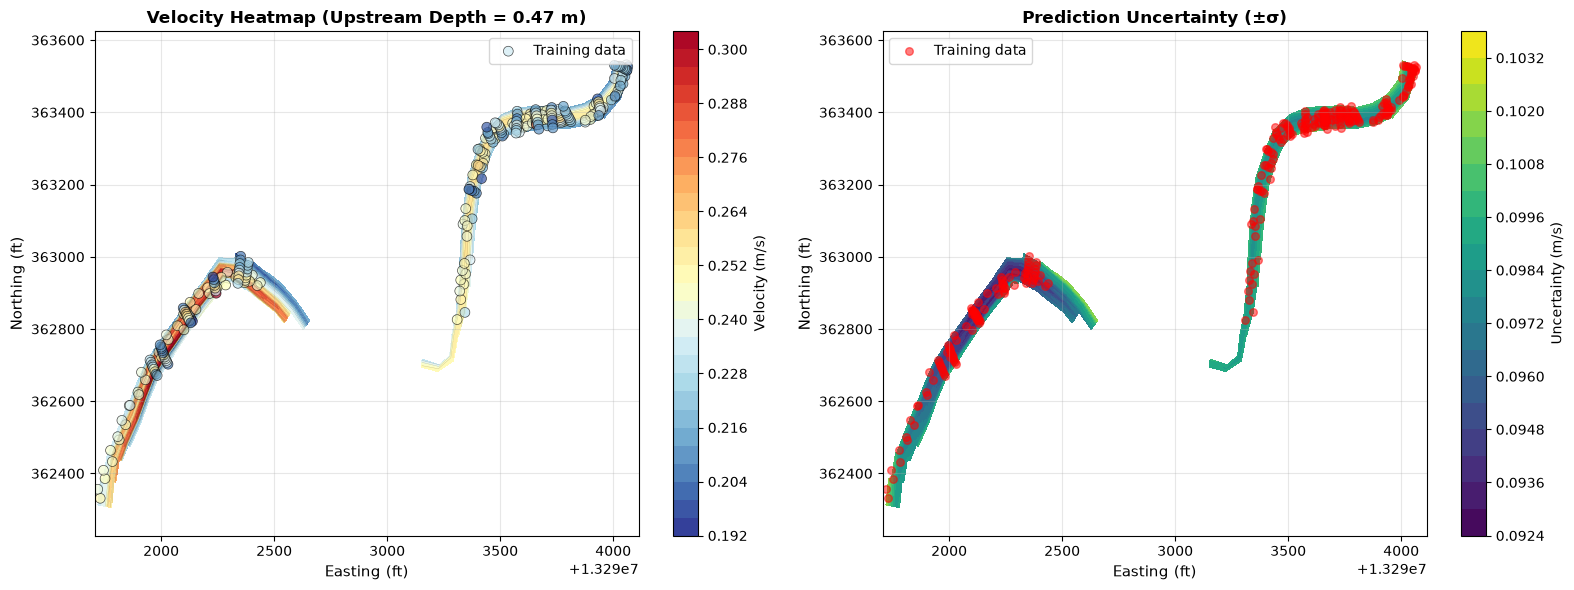

✓ Visualization complete!

STEP 7 (Optional): Exporting results


In [3]:
### 10) Project Model Back to NAD 1983 State Plane Michigan South (feet)

# Option to use mean upstream depth from training data
upstream_depth_value = gp_data_3v['upstream_depth'].mean()

# Define grid resolution (adjust as needed for smoothness vs computation time)
grid_resolution = 50  # Number of points along each dimension (increased for smoother results)

# =====================================================================
# STEP 1: GET REFERENCE DISTANCE AND CENTERLINE
# =====================================================================

print("="*80)
print("STEP 1: Setting up centerline reference")
print("="*80)

# Get the centerline geometry
centerline = gpd.read_file("../mapping/centerline_union_Upper.geojson")
centerline_geom = centerline.geometry.iloc[0]

print(f"Centerline geometry type: {centerline_geom.geom_type}")

# from above dict of GP pickle
print(f"Reference distance along centerline: {reference_distance:.2f} meters")

# DIAGNOSTIC: Check if reference_distance matches what was used to create downstream_dist
print(f"\nDiagnostic check:")
print(f"Min downstream_dist in gp_data_3v: {gp_data_3v['downstream_dist'].min():.2f}")
print(f"Expected: if downstream_dist was calculated correctly, min should be ~0")
print(f"Actual min downstream_dist value: {gp_data_3v['downstream_dist'].min():.6f}")

# =====================================================================
# STEP 2: DEFINE INVERSE TRANSFORMATION FUNCTION
# =====================================================================

print("\n" + "="*80)
print("STEP 2: Defining inverse transformation function")
print("="*80)

def model_to_spatial(downstream_dist, distance_to_centerline):
    """
    Transform from model input space to spatial coordinates using geometric inversion.
    
    Parameters:
    -----------
    downstream_dist : array-like
        Downstream distance(s) in meters (from SI-converted gp_data_3v)
    distance_to_centerline : array-like
        Signed distance to centerline in meters
        (negative = left of centerline, positive = right)
    
    Returns:
    --------
    easting, northing : arrays
        Spatial coordinates (in feet, matching the CRS)
    """
    # Ensure inputs are numpy arrays
    downstream_dist = np.atleast_1d(downstream_dist)
    distance_to_centerline = np.atleast_1d(distance_to_centerline)
    
    easting_list = []
    northing_list = []
    
    # CRITICAL FIX: Convert meters back to feet to match CRS units
    # The centerline geometry and reference_distance are in feet (State Plane CRS)
    # but ds_dist and cl_dist from gp_data_3v are in meters (converted in Cell 29)
    M_TO_FT = 1.0 / FT_TO_M  # = 1/0.3048 ≈ 3.28084
    
    for ds_dist, cl_dist in zip(downstream_dist, distance_to_centerline):
        # Convert from meters to feet before using with centerline geometry
        ds_dist_ft = ds_dist * M_TO_FT
        cl_dist_ft = cl_dist * M_TO_FT
        
        # Step 1: Get point on centerline at this downstream distance
        distance_along_line = reference_distance + ds_dist_ft  # both now in feet
        point_on_centerline = centerline_geom.interpolate(distance_along_line)
        
        # Step 2: Get the direction along the centerline at this point
        # by sampling two nearby points and computing the tangent vector
        epsilon = 0.1  # Small offset for numerical differentiation (in feet)
        p1 = centerline_geom.interpolate(max(0, distance_along_line - epsilon))
        p2 = centerline_geom.interpolate(min(centerline_geom.length, distance_along_line + epsilon))
        
        # Tangent vector (direction along centerline)
        tangent_x = p2.x - p1.x
        tangent_y = p2.y - p1.y
        tangent_length = np.sqrt(tangent_x**2 + tangent_y**2)
        
        if tangent_length < 1e-6:
            # Degenerate case, use the point as-is
            easting_list.append(point_on_centerline.x)
            northing_list.append(point_on_centerline.y)
        else:
            # Normalize tangent vector
            tangent_x /= tangent_length
            tangent_y /= tangent_length
            
            # Perpendicular rotated -90 deg from tangent = RIGHT of downstream.
            # Must match distances_to_line() in dataSorting cell 11. Do not change
            # one without the other.
            perp_x = tangent_y
            perp_y = -tangent_x
            
            # Apply the perpendicular offset (both in feet now)
            final_x = point_on_centerline.x + perp_x * cl_dist_ft
            final_y = point_on_centerline.y + perp_y * cl_dist_ft
            
            easting_list.append(final_x)
            northing_list.append(final_y)
    
    return np.array(easting_list), np.array(northing_list)

print("✓ Inverse transformation function defined")

# Round-trip check: known points -> (s, n) -> back to map coordinates.
# A left/right sign error gives ~2x the channel half-width, not a small wobble.
_E, _N = model_to_spatial(gp_data_3v['downstream_dist'].values,
                          gp_data_3v['distance_to_centerline'].values)
_err = np.nanmedian(np.hypot(_E - gp_data_3v['Easting'].values,
                             _N - gp_data_3v['Northing'].values))
assert _err < 5.0, f"MAP IS MIRRORED: {_err:.1f} ft round-trip error (expect < 5 ft)"
print(f"reach frame OK: round-trip {_err:.2f} ft")

# =====================================================================
# STEP 3: CREATE GRID IN MODEL INPUT SPACE
# =====================================================================

print("\n" + "="*80)
print("STEP 3: Creating grid in model input space")
print("="*80)

# Define grid resolution (adjust as needed for smoothness vs computation time)
grid_resolution = 50  # Number of points along each dimension (increased for smoother results)

# Spatial domain is the surveyed waterline polygon (maximum-stage streambed),
# not the training-data bounding box and not an area-of-applicability mask.
# Predict everywhere inside it; the GP posterior sd carries extrapolation
# uncertainty for poorly sampled water.
channel_extent_gdf = gpd.read_file(f'../mapping/channel_extent_{section_name}.geojson')
channel_extent = channel_extent_gdf.union_all()

def _extent_coords(geom):
    if geom.geom_type == 'Polygon':
        return [np.asarray(geom.exterior.coords)]
    return [np.asarray(p.exterior.coords) for p in geom.geoms]

def spatial_to_model(easting, northing):
    """(Easting, Northing) ft -> (downstream_dist, distance_to_centerline) m.

    Inverse of model_to_spatial; same right-of-downstream sign convention.
    """
    easting = np.atleast_1d(np.asarray(easting, dtype=float))
    northing = np.atleast_1d(np.asarray(northing, dtype=float))
    ds = np.empty(easting.size)
    cl = np.empty(easting.size)
    length = centerline_geom.length
    for i, (e, n) in enumerate(zip(easting.ravel(), northing.ravel())):
        pt = Point(float(e), float(n))
        s_ft = float(centerline_geom.project(pt))
        here = centerline_geom.interpolate(s_ft)
        back = centerline_geom.interpolate(max(s_ft - 1.0, 0.0))
        ahead = centerline_geom.interpolate(min(s_ft + 1.0, length))
        dx, dy = ahead.x - back.x, ahead.y - back.y
        d = np.hypot(dx, dy) or 1.0
        nx, ny = dy / d, -dx / d
        ds[i] = (s_ft - reference_distance) * FT_TO_M
        cl[i] = ((e - here.x) * nx + (n - here.y) * ny) * FT_TO_M
    return ds.reshape(easting.shape), cl.reshape(easting.shape)

_poly_ds, _poly_cl = [], []
for _xy in _extent_coords(channel_extent):
    _d, _c = spatial_to_model(_xy[:, 0], _xy[:, 1])
    _poly_ds.append(_d)
    _poly_cl.append(_c)
_poly_ds = np.concatenate(_poly_ds)
_poly_cl = np.concatenate(_poly_cl)

# Box must cover the waterline, which is wider than the wet-point survey.
downstream_min = min(gp_data_3v['downstream_dist'].min(), float(_poly_ds.min()))
downstream_max = max(gp_data_3v['downstream_dist'].max(), float(_poly_ds.max()))
centerline_min = min(gp_data_3v['distance_to_centerline'].min(), float(_poly_cl.min()))
centerline_max = max(gp_data_3v['distance_to_centerline'].max(), float(_poly_cl.max()))
_ds_pad = 0.02 * (downstream_max - downstream_min)
_cl_pad = 0.02 * (centerline_max - centerline_min)
downstream_min -= _ds_pad
downstream_max += _ds_pad
centerline_min -= _cl_pad
centerline_max += _cl_pad

print(f"Downstream distance range (waterline box): [{downstream_min:.2f}, {downstream_max:.2f}] m")
print(f"Centerline distance range (waterline box): [{centerline_min:.2f}, {centerline_max:.2f}] m")

# Create 1D arrays for grid
downstream_grid_1d = np.linspace(downstream_min, downstream_max, grid_resolution)
centerline_grid_1d = np.linspace(centerline_min, centerline_max, grid_resolution)

# Create 2D mesh grid
downstream_mesh, centerline_mesh = np.meshgrid(downstream_grid_1d, centerline_grid_1d)

print(f"✓ Grid created: {grid_resolution} × {grid_resolution} = {grid_resolution**2} points")

# =====================================================================
# STEP 4: EVALUATE GP MODEL ON GRID
# =====================================================================

print("\n" + "="*80)
print("STEP 4: Evaluating GP model on grid")
print("="*80)

# Flatten grid for prediction
downstream_flat = downstream_mesh.flatten()
centerline_flat = centerline_mesh.flatten()

upstream_depth_value = upstream_depth_value # set above for interactive setup BUT must be converted

print(f"Using fixed upstream depth: {upstream_depth_value:.3f} m")

# Create input array with all three dimensions
X_grid = np.column_stack([
    np.full_like(downstream_flat, upstream_depth_value),  # upstream_depth (fixed)
    downstream_flat,
    centerline_flat
])

# Scale inputs using the same scaler from training
X_grid_scaled = scaler_X_3v.transform(X_grid)

# Get predictions from GP
velocity_pred_scaled, velocity_std_scaled = gp_model_3v.predict(X_grid_scaled, return_std=True)

# Inverse transform to original scale
velocity_pred = scaler_y_3v.inverse_transform(velocity_pred_scaled.reshape(-1, 1)).ravel()
velocity_std = velocity_std_scaled * scaler_y_3v.scale_

# Reshape back to 2D grid
velocity_grid = velocity_pred.reshape(downstream_mesh.shape)
velocity_std_grid = velocity_std.reshape(downstream_mesh.shape)

# Clip negative velocities to zero (physically unrealistic)
velocity_grid = np.clip(velocity_grid, 0, None)

print(f"✓ Predictions complete")
print(f"Velocity range: [{velocity_pred.min():.4f}, {velocity_pred.max():.4f}] m/s (before clipping)")
print(f"Velocity range: [{velocity_grid.min():.4f}, {velocity_grid.max():.4f}] m/s (after clipping negative values)")

# =====================================================================
# STEP 5: TRANSFORM GRID TO SPATIAL COORDINATES
# =====================================================================

print("\n" + "="*80)
print("STEP 5: Transforming grid to spatial coordinates (geometric inversion)")
print("="*80)

# Transform grid points to spatial coordinates using geometric inversion
easting_grid_flat, northing_grid_flat = model_to_spatial(downstream_flat, centerline_flat)
easting_grid = easting_grid_flat.reshape(downstream_mesh.shape)
northing_grid = northing_grid_flat.reshape(downstream_mesh.shape)

print(f"✓ Grid transformed to spatial coordinates")
print(f"Easting range: [{easting_grid.min():.2f}, {easting_grid.max():.2f}] ft")
print(f"Northing range: [{northing_grid.min():.2f}, {northing_grid.max():.2f}] ft")

in_channel_flat = gpd.GeoSeries(
    gpd.points_from_xy(easting_grid_flat, northing_grid_flat),
    crs=channel_extent_gdf.crs,
).intersects(channel_extent).to_numpy()
in_channel_grid = in_channel_flat.reshape(downstream_mesh.shape)
print(f"Waterline mask: {int(in_channel_flat.sum())} / {in_channel_flat.size} cells "
      f"({100 * in_channel_flat.mean():.0f}% of the (ds, n) box)")

velocity_grid = np.where(in_channel_grid, velocity_grid, np.nan)
velocity_std_grid = np.where(in_channel_grid, velocity_std_grid, np.nan)

# =====================================================================
# STEP 6: VISUALIZE SPATIAL HEATMAP
# =====================================================================

print("\n" + "="*80)
print("STEP 6: Creating spatial heatmap visualization")
print("="*80)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# Plot 1: Heatmap in spatial coordinates
contourf = ax1.contourf(easting_grid, northing_grid, velocity_grid, levels=30, cmap='RdYlBu_r')
contour = ax1.contour(easting_grid, northing_grid, velocity_grid, levels=15, colors='black', alpha=0.2, linewidths=0.3)

# Overlay training data points
scatter = ax1.scatter(gp_data_3v['Easting'], gp_data_3v['Northing'], 
                      c=gp_data_3v['Velocity'], s=50, cmap='RdYlBu_r', 
                      edgecolors='black', linewidth=0.5, alpha=0.7, label='Training data')

ax1.set_xlabel('Easting (ft)', fontsize=11)
ax1.set_ylabel('Northing (ft)', fontsize=11)
ax1.set_title(f'Velocity Heatmap (Upstream Depth = {upstream_depth_value:.2f} m)', fontsize=12, fontweight='bold')
ax1.legend(loc='upper right')
ax1.grid(True, alpha=0.3)
cbar1 = plt.colorbar(contourf, ax=ax1, label='Velocity (m/s)')

# Plot 2: Prediction uncertainty in spatial coordinates
contourf_std = ax2.contourf(easting_grid, northing_grid, velocity_std_grid, levels=20, cmap='viridis')
ax2.scatter(gp_data_3v['Easting'], gp_data_3v['Northing'], 
           s=30, c='red', alpha=0.5, label='Training data')
ax2.set_xlabel('Easting (ft)', fontsize=11)
ax2.set_ylabel('Northing (ft)', fontsize=11)
ax2.set_title('Prediction Uncertainty (±σ)', fontsize=12, fontweight='bold')
ax2.legend(loc='upper left')
ax2.grid(True, alpha=0.3)
cbar2 = plt.colorbar(contourf_std, ax=ax2, label='Uncertainty (m/s)')

plt.tight_layout()
plt.show()

print(f"✓ Visualization complete!")

# =====================================================================
# OPTIONAL: EXPORT RESULTS TO GEOJSON OR CSV
# =====================================================================

print("\n" + "="*80)
print("STEP 7 (Optional): Exporting results")
print("="*80)

# Create a dataframe with grid results
results_df = pd.DataFrame({
    'easting': easting_grid_flat,
    'northing': northing_grid_flat,
    'velocity': velocity_pred,
    'velocity_uncertainty': velocity_std,
    'downstream_dist': downstream_flat,
    'distance_to_centerline': centerline_flat
})


In [4]:
### 11) Interactive Spatial GP Model Visualization with Upstream Depth Slider
# =====================================================================
# Interactive visualization of projected GP model output in spatial coordinates
# Uses single slider for upstream depth to update both velocity and uncertainty plots
# =====================================================================
fontX = 1.5

print("="*80)
print("INTERACTIVE SPATIAL GP MODEL VISUALIZATION")
print("="*80)

# Get upstream depth range from training data (already in SI units - meters)
upstream_depth_min_spatial = gp_data_3v['upstream_depth'].min()
upstream_depth_max_spatial = gp_data_3v['upstream_depth'].max()
upstream_depth_median_spatial = gp_data_3v['upstream_depth'].median()

print(f"\nUpstream Depth Range: [{upstream_depth_min_spatial:.3f}, {upstream_depth_max_spatial:.3f}] m")
print(f"Grid Resolution: {grid_resolution} × {grid_resolution} = {grid_resolution**2} points")

def plot_spatial_heatmap_interactive(upstream_depth):
    """
    Generate interactive spatial heatmap for given upstream_depth value.
    Shows both velocity predictions and uncertainty in spatial coordinates.
    
    Parameters:
    -----------
    upstream_depth : float
        Upstream depth value in meters (SI units)
    """
    # Create input array with the selected upstream depth
    X_grid_interactive = np.column_stack([
        np.full_like(downstream_flat, upstream_depth),  # upstream_depth (from slider)
        downstream_flat,                                 # downstream_dist
        centerline_flat                                  # distance_to_centerline
    ])
    
    # Scale inputs using the same scaler from training
    X_grid_interactive_scaled = scaler_X_3v.transform(X_grid_interactive)
    
    # Get predictions from GP with uncertainty
    velocity_pred_interactive_scaled, velocity_std_interactive_scaled = gp_model_3v.predict(
        X_grid_interactive_scaled, return_std=True
    )
    
    # Inverse transform to original scale
    velocity_pred_interactive = scaler_y_3v.inverse_transform(
        velocity_pred_interactive_scaled.reshape(-1, 1)
    ).ravel()
    velocity_std_interactive = velocity_std_interactive_scaled * scaler_y_3v.scale_
    
    # Reshape back to 2D grid
    velocity_grid_interactive = velocity_pred_interactive.reshape(downstream_mesh.shape)
    velocity_std_grid_interactive = velocity_std_interactive.reshape(downstream_mesh.shape)
    
    # Clip negative velocities to zero (physically unrealistic)
    velocity_grid_interactive = np.clip(velocity_grid_interactive, 0, None)
    velocity_grid_interactive = np.where(in_channel_grid, velocity_grid_interactive, np.nan)
    velocity_std_grid_interactive = np.where(in_channel_grid, velocity_std_grid_interactive, np.nan)
    
    # Create figure with two subplots
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(20, 10))
    
    # ===== Plot 1: Velocity Heatmap in Spatial Coordinates =====
    contourf1 = ax1.contourf(
        easting_grid, northing_grid, velocity_grid_interactive, 
        levels=30, cmap='viridis' ########################3
    )
    contour1 = ax1.contour(
        easting_grid, northing_grid, velocity_grid_interactive, 
        levels=15, colors='black', alpha=0.2, linewidths=0.3
    )
    '''
    # Overlay training data points
    scatter1 = ax1.scatter(
        gp_data_3v['Easting'], gp_data_3v['Northing'], 
        c=gp_data_3v['Velocity'], s=60, cmap='viridis', 
        edgecolors='black', linewidth=0.8, alpha=0.8, 
        label='Training Data', zorder=10
    )
    '''
    ax1.set_xlabel('Easting (ft)', fontsize=12*fontX)
    ax1.set_ylabel('Northing (ft)', fontsize=12*fontX)
    ax1.set_title(
        f'Velocity Prediction (Spatial Coordinates)\n'
        f'Upstream Depth = {upstream_depth:.3f} m',
        fontsize=13*fontX, fontweight='bold'
    )
    ax1.legend(loc='upper right', fontsize=10*fontX, framealpha=0.9)
    ax1.grid(True, alpha=0.3)
    cbar1 = plt.colorbar(contourf1, ax=ax1)
    cbar1.set_label('Velocity (m/s)', fontsize=11*fontX)
    
    # ===== Plot 2: Prediction Uncertainty in Spatial Coordinates =====
    contourf2 = ax2.contourf(
        easting_grid, northing_grid, velocity_std_grid_interactive, 
        levels=20, cmap='viridis'
    )
    '''
    # Overlay training data points
    scatter2 = ax2.scatter(
        gp_data_3v['Easting'], gp_data_3v['Northing'], 
        s=40, c='red', alpha=0.6, label='Training Data', zorder=10
    )
    '''
    ax2.set_xlabel('Easting (ft)', fontsize=12*fontX)
    ax2.set_ylabel('Northing (ft)', fontsize=12*fontX)
    ax2.set_title(
        f'Prediction Uncertainty (±σ)\n'
        f'Upstream Depth = {upstream_depth:.3f} m',
        fontsize=13*fontX, fontweight='bold'
    )
    ax2.legend(loc='upper left', fontsize=10*fontX, framealpha=0.9)
    ax2.grid(True, alpha=0.3)
    cbar2 = plt.colorbar(contourf2, ax=ax2)
    cbar2.set_label('Uncertainty (m/s)', fontsize=11*fontX)
    
    plt.tight_layout()
    plt.show()
    
    # Print statistics
    print(f"\n--- Model Output Statistics ---")
    print(f"  Upstream Depth: {upstream_depth:.4f} m ({upstream_depth / FT_TO_M:.3f} ft)")
    print(f"  Velocity Range: [{velocity_grid_interactive.min():.4f}, {velocity_grid_interactive.max():.4f}] m/s")
    print(f"  Mean Velocity: {velocity_grid_interactive.mean():.4f} m/s")
    print(f"  Uncertainty Range: [{velocity_std_grid_interactive.min():.4f}, {velocity_std_grid_interactive.max():.4f}] m/s")
    print(f"  Mean Uncertainty: {velocity_std_grid_interactive.mean():.4f} m/s")

# Create interactive widget with slider
print(f"\n✓ Interactive Spatial Visualization Ready!")
print(f"\nUse the slider below to adjust Upstream Depth:")

interact(
    plot_spatial_heatmap_interactive,
    upstream_depth=FloatSlider(
        value=upstream_depth_median_spatial,
        min=upstream_depth_min_spatial,
        max=upstream_depth_max_spatial,
        step=(upstream_depth_max_spatial - upstream_depth_min_spatial) / 50,
        description='Upstream Depth (m):',
        continuous_update=False,
        style={'description_width': '150px'},
        layout={'width': '600px'}
    )
)

INTERACTIVE SPATIAL GP MODEL VISUALIZATION

Upstream Depth Range: [0.307, 0.701] m
Grid Resolution: 50 × 50 = 2500 points

✓ Interactive Spatial Visualization Ready!

Use the slider below to adjust Upstream Depth:


interactive(children=(FloatSlider(value=0.4823000154336, continuous_update=False, description='Upstream Depth …

<function __main__.plot_spatial_heatmap_interactive(upstream_depth)>

In [5]:
### 12) Interactive Binary Threshold Visualization (Velocity > 0.2 m/s)
# =====================================================================
# Binary color visualization: Red = velocity > threshold, Green = velocity <= threshold
# Uses single slider for upstream depth
# =====================================================================
fontX = 1.5

print("="*80)
print("INTERACTIVE BINARY THRESHOLD VISUALIZATION")
print("="*80)

# Define velocity threshold
VELOCITY_THRESHOLD = 0.2  # m/s

print(f"\nVelocity Threshold: {VELOCITY_THRESHOLD} m/s")
print(f"  Red = velocity > {VELOCITY_THRESHOLD} m/s (high velocity)")
print(f"  Green = velocity ≤ {VELOCITY_THRESHOLD} m/s (low velocity)")

# Get upstream depth range from training data (already in SI units - meters)
upstream_depth_min_binary = gp_data_3v['upstream_depth'].min()
upstream_depth_max_binary = gp_data_3v['upstream_depth'].max()
upstream_depth_median_binary = gp_data_3v['upstream_depth'].median()

# Create binary colormap: 0 = green, 1 = red
binary_cmap = ListedColormap(['#2ecc71', '#e74c3c'])  # Green, Red

def calculate_area_below_threshold(upstream_depth, return_bounds=False):
    """Calculate percentage of area below velocity threshold for given upstream depth.
    
    If return_bounds=True, also returns lower and upper bounds based on GP uncertainty.
    """
    X_grid = np.column_stack([
        np.full_like(downstream_flat, upstream_depth),
        downstream_flat,
        centerline_flat
    ])
    X_grid_scaled = scaler_X_3v.transform(X_grid)
    
    # Get predictions with uncertainty
    vel_pred_scaled, vel_std_scaled = gp_model_3v.predict(X_grid_scaled, return_std=True)
    vel_pred = scaler_y_3v.inverse_transform(vel_pred_scaled.reshape(-1, 1)).ravel()
    vel_std = vel_std_scaled * scaler_y_3v.scale_
    
    vel_pred = np.clip(vel_pred, 0, None)
    # Percentages are of the waterline, not the rectangular (ds, n) box.
    _wet = in_channel_flat
    area_mean = ((vel_pred[_wet] <= VELOCITY_THRESHOLD).sum() / _wet.sum()) * 100
    
    if return_bounds:
        # Lower bound: using (vel + std) - fewer points will be below threshold
        vel_upper = np.clip(vel_pred + vel_std, 0, None)
        area_lower = ((vel_upper[_wet] <= VELOCITY_THRESHOLD).sum() / _wet.sum()) * 100
        
        # Upper bound: using (vel - std) - more points will be below threshold
        vel_lower = np.clip(vel_pred - vel_std, 0, None)
        area_upper = ((vel_lower[_wet] <= VELOCITY_THRESHOLD).sum() / _wet.sum()) * 100
        
        return area_mean, area_lower, area_upper
    
    return area_mean

# Pre-calculate area for all depth values with uncertainty bounds (used for line plot in next cell)
upstream_depth_values = np.linspace(upstream_depth_min_binary, upstream_depth_max_binary, 50)
area_below_threshold_values = []
area_lower_bounds = []
area_upper_bounds = []

for d in upstream_depth_values:
    mean, lower, upper = calculate_area_below_threshold(d, return_bounds=True)
    area_below_threshold_values.append(mean)
    area_lower_bounds.append(lower)
    area_upper_bounds.append(upper)

print(f"✓ Pre-calculated area with uncertainty for {len(upstream_depth_values)} depth values")

def plot_binary_threshold_interactive(upstream_depth):
    """
    Generate interactive binary threshold heatmap for given upstream_depth value.
    Red indicates velocity above threshold, Green indicates velocity at or below threshold.
    
    Parameters:
    -----------
    upstream_depth : float
        Upstream depth value in meters (SI units)
    """
    # Create input array with the selected upstream depth
    X_grid_binary = np.column_stack([
        np.full_like(downstream_flat, upstream_depth),  # upstream_depth (from slider)
        downstream_flat,                                 # downstream_dist
        centerline_flat                                  # distance_to_centerline
    ])
    
    # Scale inputs using the same scaler from training
    X_grid_binary_scaled = scaler_X_3v.transform(X_grid_binary)
    
    # Get predictions from GP
    velocity_pred_binary_scaled = gp_model_3v.predict(X_grid_binary_scaled)
    
    # Inverse transform to original scale
    velocity_pred_binary = scaler_y_3v.inverse_transform(
        velocity_pred_binary_scaled.reshape(-1, 1)
    ).ravel()
    
    # Reshape back to 2D grid
    velocity_grid_binary = velocity_pred_binary.reshape(downstream_mesh.shape)
    
    # Clip negative velocities to zero
    velocity_grid_binary = np.clip(velocity_grid_binary, 0, None)
    velocity_grid_binary = np.where(in_channel_grid, velocity_grid_binary, np.nan)
    
    # Create binary classification: 1 = above threshold (red), 0 = below threshold (green)
    # NaN outside the waterline so dry land is not coloured or counted.
    binary_grid = np.where(in_channel_grid,
                           (velocity_grid_binary > VELOCITY_THRESHOLD).astype(float),
                           np.nan)
    
    # Create figure
    fig, ax = plt.subplots(figsize=(12, 10))
    
    # Plot binary heatmap
    im = ax.pcolormesh(
        easting_grid, northing_grid, binary_grid,
        cmap=binary_cmap, shading='auto',
        vmin=0, vmax=1
    )
    
    # Add contour line at threshold
    contour_threshold = ax.contour(
        easting_grid, northing_grid, velocity_grid_binary,
        levels=[VELOCITY_THRESHOLD], colors='black', linewidths=2.5, linestyles='--'
    )
    ax.clabel(contour_threshold, fmt=f'{VELOCITY_THRESHOLD} m/s', fontsize=11*fontX, inline=True)
    
    # # Overlay training data points with binary coloring
    # training_colors = ['#2ecc71' if v <= VELOCITY_THRESHOLD else '#e74c3c' 
    #                    for v in gp_data_3v['Velocity']]
    # scatter = ax.scatter(
    #     gp_data_3v['Easting'], gp_data_3v['Northing'],
    #     c=training_colors, s=80,
    #     edgecolors='black', linewidth=1.2, alpha=0.9,
    #     label='Training Data', zorder=10
    # )
    
    # Labels and title
    ax.set_xlabel('Easting (ft)', fontsize=13*fontX)
    ax.set_ylabel('Northing (ft)', fontsize=13*fontX)
    ax.set_title(
        f'Binary Velocity Classification (Threshold = {VELOCITY_THRESHOLD} m/s)\n'
        f'Upstream Depth = {upstream_depth:.3f} m',
        fontsize=14*fontX, fontweight='bold'
    )
    ax.grid(True, alpha=0.3)
    
    # Calculate statistics over the waterline only
    _wet2d = in_channel_grid
    above_threshold_pct = (np.nansum(binary_grid == 1) / _wet2d.sum()) * 100
    below_threshold_pct = 100 - above_threshold_pct
    
    # Create custom legend
    legend_elements = [
        Patch(facecolor='#e74c3c', edgecolor='black', label=f'Velocity > {VELOCITY_THRESHOLD} m/s (High)'),
        Patch(facecolor='#2ecc71', edgecolor='black', label=f'Velocity ≤ {VELOCITY_THRESHOLD} m/s (Low)'),
        plt.Line2D([0], [0], color='black', linewidth=2.5, linestyle='--', 
                   label=f'Threshold ({VELOCITY_THRESHOLD} m/s)')
    ]
    legend = ax.legend(handles=legend_elements, loc='upper right', fontsize=11*fontX, framealpha=0.95)
    
    # Add area below threshold text underneath the legend
    # Get legend bounding box to position text below it
    ax.text(0.98, 0.76, f'Area below threshold: {below_threshold_pct:.1f}%',
            transform=ax.transAxes, fontsize=11*fontX, fontweight='bold',
            verticalalignment='top', horizontalalignment='right',
            bbox=dict(boxstyle='round', facecolor='#2ecc71', edgecolor='black', alpha=0.8))
    
    plt.tight_layout()
    plt.show()
    
    print(f"\n--- Binary Classification Statistics ---")
    print(f"  Upstream Depth: {upstream_depth:.4f} m ({upstream_depth / FT_TO_M:.3f} ft)")
    print(f"  Velocity Threshold: {VELOCITY_THRESHOLD} m/s")
    print(f"  Area above threshold (Red): {above_threshold_pct:.1f}%")
    print(f"  Area at/below threshold (Green): {below_threshold_pct:.1f}%")
    print(f"  Velocity Range: [{velocity_grid_binary.min():.4f}, {velocity_grid_binary.max():.4f}] m/s")

# Create interactive widget with slider
print(f"\n✓ Interactive Binary Visualization Ready!")
print(f"\nUse the slider below to adjust Upstream Depth:")

interact(
    plot_binary_threshold_interactive,
    upstream_depth=FloatSlider(
        value=upstream_depth_median_binary,
        min=upstream_depth_min_binary,
        max=upstream_depth_max_binary,
        step=(upstream_depth_max_binary - upstream_depth_min_binary) / 50,
        description='Upstream Depth (m):',
        continuous_update=False,
        style={'description_width': '150px'},
        layout={'width': '600px'}
    )
)

INTERACTIVE BINARY THRESHOLD VISUALIZATION

Velocity Threshold: 0.2 m/s
  Red = velocity > 0.2 m/s (high velocity)
  Green = velocity ≤ 0.2 m/s (low velocity)
✓ Pre-calculated area with uncertainty for 50 depth values

✓ Interactive Binary Visualization Ready!

Use the slider below to adjust Upstream Depth:


interactive(children=(FloatSlider(value=0.4823000154336, continuous_update=False, description='Upstream Depth …

<function __main__.plot_binary_threshold_interactive(upstream_depth)>

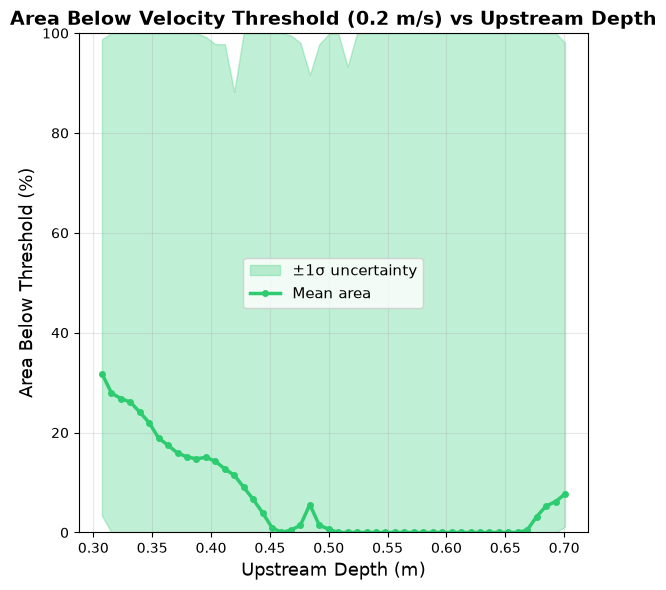

In [6]:
### 13) Area Below Threshold vs Upstream Depth
# =====================================================================
# Line plot using pre-calculated area values with uncertainty bounds
# =====================================================================

fig, ax = plt.subplots(figsize=(6, 6))

# Plot uncertainty band (±1σ based on GP model uncertainty)
ax.fill_between(upstream_depth_values, area_lower_bounds, area_upper_bounds,
                alpha=0.3, color='#2ecc71', label='±1σ uncertainty')

# Plot mean line
ax.plot(upstream_depth_values, area_below_threshold_values, 
        color='#2ecc71', linewidth=2.5, marker='o', markersize=4, label='Mean area')

ax.set_xlabel('Upstream Depth (m)', fontsize=13)
ax.set_ylabel('Area Below Threshold (%)', fontsize=13)
ax.set_title(f'Area Below Velocity Threshold ({VELOCITY_THRESHOLD} m/s) vs Upstream Depth',
             fontsize=14, fontweight='bold')
ax.set_ylim(0, 100)
ax.grid(True, alpha=0.3)
ax.legend(loc='best', fontsize=11)

plt.tight_layout()
plt.show()


PROBABILISTIC THRESHOLD ANALYSIS - Upper

Variance decomposition (standardised units):
  WhiteKernel noise_level      : 0.0931
  -> observation noise sd       : 0.0280 m/s

Waterline domain (fixed across stages):
  map   grid 220 x 220 ->  15899 in-channel cells (33% of the bounding box); cell  4.97 m x 0.22 m
  area  grid  64 x 64  ->   1314 in-channel cells (32% of the bounding box); cell 17.09 m x 0.77 m
  waterline coverage agreement between the two grids: 0.8 percentage points of the bounding box (OK)

Resolution vs kernel:
  fitted kernel: 0.856**2 * RBF(length_scale=[0.01, 0.0445, 0.607]) + RationalQuadratic(alpha=0.141, length_scale=0.243) + WhiteKernel(noise_level=0.0931)
  RBF upstream_depth           l =  0.010 std =     0.001 m   <-- AT LOWER BOUND
  RBF downstream_dist          l =  0.044 std =    15.591 m   <-- AT LOWER BOUND
  RBF distance_to_centerline   l =  0.607 std =     3.793 m
  map cell size: 4.97 m along, 0.22 m across
  NOTE: at least one RBF length scale sits 

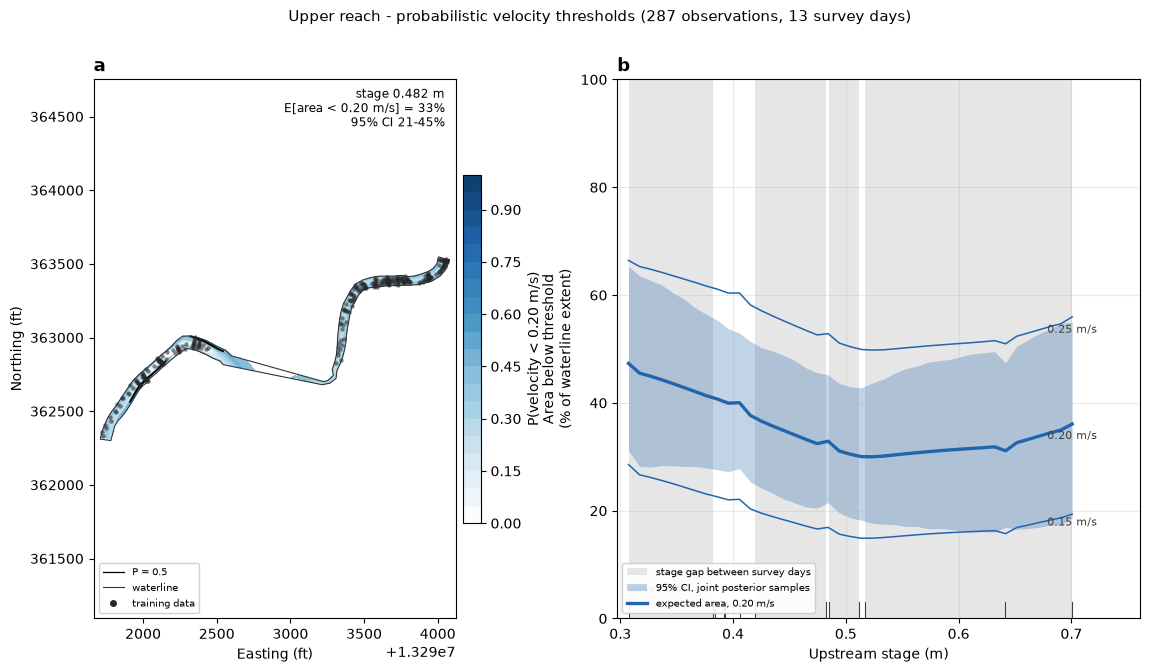


AREA BELOW THRESHOLD, Upper (% of waterline extent)
 stage (m)             <0.15 m/s             <0.20 m/s             <0.25 m/s
     0.307          29% [16-44]          47% [31-65]          66% [50-82]
     0.356          24% [13-38]          43% [28-59]          63% [48-78]
     0.406          22% [13-32]          40% [28-53]          60% [48-74]
     0.455          18% [9-28]          34% [21-48]          54% [41-69]
     0.504          15% [7-25]          30% [19-43]          50% [36-65]
     0.553          15% [7-27]          31% [17-46]          50% [34-68]
     0.602          16% [6-30]          31% [16-49]          51% [33-70]
     0.652          17% [7-31]          33% [17-51]          52% [34-72]
     0.701          19% [8-35]          36% [19-55]          56% [36-75]

ASSUMPTIONS BEHIND THIS FIGURE
  1. Smoothness is the GP's, not the plot's. Panel (a) is the posterior
     evaluated on a 220 x 220 grid; no spatial filter is applied to the
     velocity or probability field

In [7]:
### 14) Probabilistic Threshold Analysis
# =====================================================================
#   (a) P(mean velocity < threshold) over the reach, masked to the surveyed
#       waterline (mapping/channel_extent_{section}.geojson), with the P = 0.5
#       contour. Poorly sampled water is KEPT; the GP posterior sd is the
#       applicability statement.
#   (b) Expected area below 0.15 / 0.20 / 0.25 m/s against upstream stage, with
#       95% CI from JOINT posterior samples (not the +/-1 sigma envelope).
#
# ON SMOOTHNESS - read this before changing the resolution knobs
# --------------------------------------------------------------
# Everything this cell does to make the figure smoother is either (1) evaluating
# the SAME posterior on a finer grid, or (2) reducing Monte Carlo noise. Neither
# changes the estimand. No post-hoc spatial filter is applied to the velocity or
# probability field: the GP posterior is already the smoothed estimate, and
# blurring it again would understate structure the model actually claims.
#
# The consequence is that a finer grid can look ROUGHER, not smoother, because it
# resolves fine structure the kernel genuinely contains. If the map is striped at
# high resolution, that is the fitted kernel talking, not the plot - see the
# "resolution vs kernel" block this cell prints. The fix for that is refitting
# (ARD Matern, wider length_scale_bounds), not filtering the picture.
#
# Requires, from earlier cells in this notebook:
#   gp_model_3v, scaler_X_3v, scaler_y_3v, gp_data_3v, FT_TO_M, section_name,
#   reference_distance, centerline_geom, model_to_spatial, grid_resolution,
#   VELOCITY_THRESHOLD
#
# np, pd, plt, Line2D and LinearSegmentedColormap all come from cell 0.
# The four imports below are NOT in cell 0, so they have to stay here.
# =====================================================================

from scipy.stats import norm
from scipy.ndimage import uniform_filter, label as nd_label
from sklearn.gaussian_process.kernels import WhiteKernel

# --------------------------------------------------------------------
# CONFIGURATION
# --------------------------------------------------------------------
THRESHOLDS      = [0.15, 0.20, 0.25]          # m/s, panel (b)
MAIN_THRESHOLD  = globals().get('VELOCITY_THRESHOLD', 0.20)   # m/s, panel (a)
# Spatial domain is the surveyed waterline polygon loaded in cell 10
# (channel_extent). No area-of-applicability cutoff is applied.

# Panel (a) needs only MARGINAL predictions (mean and sd per cell), which cost
# O(n_cells). Go fine here - it is what removes the pixelated mask edge.
N_GRID_MAP      = 220
# Panel (b) needs the JOINT covariance, which costs O(n_cells^3) per stage. This
# has to stay coarse. The grid-convergence check below reports what that costs
# you in the area estimate.
N_GRID_AREA     = 64
N_GRID_CHECK    = 96        # one-off finer grid, for the convergence check only

N_STAGE         = 41        # stage values along the x-axis of panel (b)
N_SAMPLES       = 600       # joint posterior draws per stage
COMMON_RANDOM   = True      # reuse one set of draws across stages (see below)
RANDOM_STATE    = 0
PRED_CHUNK      = 4000      # query rows per prediction block, caps peak memory
# Runtime ~1-3 min for Middle, under a minute for Upper/Lower.

rng = np.random.default_rng(RANDOM_STATE)

print("=" * 80)
print(f"PROBABILISTIC THRESHOLD ANALYSIS - {section_name}")
print("=" * 80)

# --------------------------------------------------------------------
# STEP 1: separate LATENT uncertainty from observation noise
# --------------------------------------------------------------------
# gp.predict(return_std=True) returns sqrt(k(x,x) - k*' K^-1 k*), and k(x,x)
# includes the WhiteKernel term. That is the uncertainty of ONE wading-rod
# reading. The threshold question is about the MEAN velocity at a location, so
# the white-noise part must come out - otherwise P(v < threshold) is dragged
# toward 0.5 everywhere and the map carries almost no spatial information.

def _white_noise_level(kernel):
    """Total WhiteKernel noise_level anywhere in a composite kernel."""
    if isinstance(kernel, WhiteKernel):
        return float(kernel.noise_level)
    total = 0.0
    for attr in ('k1', 'k2', 'kernel'):
        if hasattr(kernel, attr):
            total += _white_noise_level(getattr(kernel, attr))
    return total

noise_scaled = _white_noise_level(gp_model_3v.kernel_)
y_scale = float(scaler_y_3v.scale_[0])

print(f"\nVariance decomposition (standardised units):")
print(f"  WhiteKernel noise_level      : {noise_scaled:.4f}")
print(f"  -> observation noise sd       : {np.sqrt(noise_scaled) * y_scale:.4f} m/s")
if noise_scaled > 0.4:
    print(f"  NOTE: {noise_scaled * 100:.0f}% of the standardised variance is being called")
    print(f"        noise. Latent uncertainty is small by comparison, so panel (a)")
    print(f"        will look confident. Read it as 'given this fit', not 'given the data'.")


def predict_velocity(X_phys, chunk=PRED_CHUNK):
    """Marginal GP prediction in m/s, observation noise removed. Chunked."""
    mu = np.empty(len(X_phys)); sd = np.empty(len(X_phys))
    for a in range(0, len(X_phys), chunk):
        b = min(a + chunk, len(X_phys))
        mu_s, sd_s = gp_model_3v.predict(scaler_X_3v.transform(X_phys[a:b]),
                                         return_std=True)
        mu[a:b] = scaler_y_3v.inverse_transform(mu_s.reshape(-1, 1)).ravel()
        sd[a:b] = np.sqrt(np.clip(sd_s ** 2 - noise_scaled, 0.0, None)) * y_scale
    return mu, sd


def latent_cholesky(X_phys):
    """Mean and a Cholesky factor of the LATENT posterior covariance (m/s).

    Subtracting the white-noise diagonal can leave a few tiny negative
    eigenvalues, so escalate jitter first and only fall back to the (much more
    expensive) eigendecomposition if Cholesky still fails.
    """
    Xs = scaler_X_3v.transform(X_phys)
    mu_s, cov_s = gp_model_3v.predict(Xs, return_cov=True)
    cov_s = cov_s - noise_scaled * np.eye(len(cov_s))
    cov_s = 0.5 * (cov_s + cov_s.T)
    mu = scaler_y_3v.inverse_transform(mu_s.reshape(-1, 1)).ravel()
    scale = float(np.mean(np.diag(cov_s))) or 1.0
    for jit in (1e-12, 1e-10, 1e-8, 1e-6, 1e-4):
        try:
            L = np.linalg.cholesky(cov_s + jit * scale * np.eye(len(cov_s)))
            return mu, L * y_scale
        except np.linalg.LinAlgError:
            continue
    w, V = np.linalg.eigh(cov_s)
    return mu, (V * np.sqrt(np.clip(w, 0, None))) @ V.T * y_scale


# --------------------------------------------------------------------
# STEP 2: waterline domain (shared by every grid)
# --------------------------------------------------------------------
# The prediction domain is mapping/channel_extent_{section}.geojson, the
# surveyed bank / waterline polygon from dataSorting cell 8. Every cell whose
# map location intersects that polygon is predicted. Cells on dry land are
# dropped. There is no kNN / area-of-applicability cutoff: sparsely sampled
# water stays in the map, and the GP posterior sd is the statement of
# applicability.
ds_train = gp_data_3v['downstream_dist'].values          # m
cl_train = gp_data_3v['distance_to_centerline'].values   # m
depth_train = gp_data_3v['upstream_depth'].values        # m

ds_lo, ds_hi = downstream_min, downstream_max
cl_lim = max(abs(centerline_min), abs(centerline_max))
reach_len = ds_hi - ds_lo

# Half-width from the wet-point survey, used ONLY for the core/bank diagnostic
# below, not as a mask.
n_bins = max(8, min(25, len(np.unique(np.round(ds_train, 1))) // 4))
bin_edges = np.linspace(ds_train.min(), ds_train.max(), n_bins + 1)
bin_mid = 0.5 * (bin_edges[:-1] + bin_edges[1:])
half_left = np.full(n_bins, np.nan)
half_right = np.full(n_bins, np.nan)
for b in range(n_bins):
    sel = (ds_train >= bin_edges[b]) & (ds_train <= bin_edges[b + 1])
    if sel.sum() >= 3:
        half_left[b] = np.abs(np.minimum(cl_train[sel].min(), 0.0))
        half_right[b] = max(cl_train[sel].max(), 0.0)

def _fill(a):
    s = pd.Series(a).interpolate(limit_direction='both')
    return s.fillna(np.nanmax(a) if np.isfinite(a).any() else np.abs(cl_train).max()).values

half_left, half_right = _fill(half_left), _fill(half_right)


def build_envelope(n_grid):
    """Grid + waterline mask + per-cell area, at a given resolution.

    The mask is point-in-polygon against channel_extent, so the coarse area
    grid and the fine map grid describe the SAME physical region.
    """
    ds_ax = np.linspace(ds_lo, ds_hi, n_grid)
    cl_ax = np.linspace(-cl_lim, cl_lim, n_grid)
    DSg, CLg = np.meshgrid(ds_ax, cl_ax, indexing='ij')
    dsf, clf = DSg.ravel(), CLg.ravel()

    ef, nf = model_to_spatial(dsf, clf)
    chan = gpd.GeoSeries(
        gpd.points_from_xy(ef, nf), crs=channel_extent_gdf.crs
    ).intersects(channel_extent).to_numpy()

    # model_to_spatial returns State Plane feet; keep those for the map and
    # convert to metres only for the area-weighted statistic.
    E_ft = ef.reshape(DSg.shape)
    N_ft = nf.reshape(DSg.shape)
    E = E_ft * FT_TO_M
    N = N_ft * FT_TO_M

    x1, y1 = E[:-1, :-1], N[:-1, :-1]; x2, y2 = E[1:, :-1], N[1:, :-1]
    x3, y3 = E[1:, 1:], N[1:, 1:];     x4, y4 = E[:-1, 1:], N[:-1, 1:]
    quad = 0.5 * np.abs((x1 * y2 - x2 * y1) + (x2 * y3 - x3 * y2) +
                        (x3 * y4 - x4 * y3) + (x4 * y1 - x1 * y4))
    area = np.zeros_like(E)
    area[:-1, :-1] += quad / 4; area[1:, :-1] += quad / 4
    area[1:, 1:] += quad / 4;   area[:-1, 1:] += quad / 4

    return dict(DS=DSg, ds=dsf, cl=clf, chan=chan, env=chan,
                E=E, N=N, E_ft=E_ft, N_ft=N_ft,
                area=area.ravel(), shape=DSg.shape)


G_map = build_envelope(N_GRID_MAP)
G_area = build_envelope(N_GRID_AREA)

stage_median = float(np.median(depth_train))

# Survey days for the rug in panel (b). Exclude the fixed-station ADCP rows:
# they contribute a stage value for every day the instrument logged, which would
# make the reach look far more intensively surveyed than it was.
_is_adcp = (gp_data_3v['Type'].astype(str).str.strip().str.lower() == 'sontek') \
    if 'Type' in gp_data_3v.columns else np.zeros(len(gp_data_3v), bool)
survey_stages = np.unique(np.round(depth_train[~np.asarray(_is_adcp)], 6))
n_survey_days = survey_stages.size

print(f"\nWaterline domain (fixed across stages):")
for nm, G in (('map  ', G_map), ('area ', G_area)):
    print(f"  {nm} grid {G['shape'][0]:>3d} x {G['shape'][1]:<3d} -> "
          f"{G['env'].sum():>6d} in-channel cells "
          f"({G['env'].mean() * 100:>2.0f}% of the bounding box); "
          f"cell {reach_len / G['shape'][0]:5.2f} m x {2 * cl_lim / G['shape'][1]:4.2f} m")
_env_gap = abs(G_map['env'].mean() - G_area['env'].mean()) * 100
print(f"  waterline coverage agreement between the two grids: "
      f"{_env_gap:.1f} percentage points of the bounding box "
      f"{'(OK)' if _env_gap < 2 else '(CHECK - grids disagree)'}")
if G_area['env'].sum() < 50:
    print("  WARNING: very few in-channel cells. Check that "
          f"mapping/channel_extent_{section_name}.geojson covers this reach.")

# --- resolution vs kernel: is the field SUPPOSED to be smooth? ---------------
# Physical correlation length = standardised length_scale x that feature's
# StandardScaler scale. If it is at the kernel's lower bound (0.1 as configured
# in gpModel), that component is a near-delta function and no amount of plotting
# resolution will make the map look smooth - it will just resolve the stripes.
print(f"\nResolution vs kernel:")
print(f"  fitted kernel: {gp_model_3v.kernel_}")
_at_bound = False
try:
    _ls = np.atleast_1d(gp_model_3v.kernel_.k1.k2.k1.length_scale)  # the ARD RBF
    _names = ['upstream_depth', 'downstream_dist', 'distance_to_centerline']
    for _i, (_n, _l) in enumerate(zip(_names, _ls)):
        _phys = _l * scaler_X_3v.scale_[_i]
        _unit = 'm'
        print(f"  RBF {_n:<24s} l = {_l:6.3f} std = {_phys:9.3f} {_unit}"
              + ("   <-- AT LOWER BOUND" if _l <= 0.1001 else ""))
        if _l <= 0.1001:
            _at_bound = True
    _cell_cross = 2 * cl_lim / G_map['shape'][1]
    print(f"  map cell size: {reach_len / G_map['shape'][0]:.2f} m along, "
          f"{_cell_cross:.2f} m across")
    if _at_bound:
        print(f"  NOTE: at least one RBF length scale sits on the lower bound, so the")
        print(f"        posterior contains structure at the scale of the data spacing.")
        print(f"        Refining the grid RESOLVES that structure rather than hiding it.")
        print(f"        If you want a genuinely smooth field, refit with an ARD Matern")
        print(f"        and wider length_scale_bounds - do not filter this figure.")
except AttributeError:
    print("  (kernel structure differs from the gpModel template; skipping)")

_lab, _n_comp = nd_label(G_area['env'].reshape(G_area['shape']))
if _n_comp > 1:
    _big = np.sort(np.bincount(_lab.ravel())[1:])[::-1]
    _frac_big = _big[0] / G_area['env'].sum()
    print(f"  waterline is {_n_comp} disconnected stretches "
          f"(largest holds {_frac_big * 100:.1f}% of the in-channel area)")
    if _frac_big < 0.80:
        print(f"  NOTE: the polygon breaks across unsurveyed gaps (dataSorting cell 8).")
        print(f"        Panel (b) percentages are of the mapped water, not of the")
        print(f"        gaps between stretches.")

# Panel (a) uses the same State Plane Easting/Northing (ft) as cell 10:
# model_to_spatial already returns feet. Plot with contourf, not pcolormesh —
# Easting/Northing are not monotonic along a bending (ds, n) grid, so
# pcolormesh infers the wrong cell edges (that was the incorrect figure).
E_ft, N_ft = G_map['E_ft'], G_map['N_ft']
_in = G_map['env']
print(f"\nPanel (a) coordinates (State Plane ft):")
print(f"  grid Easting  [{E_ft.ravel()[_in].min():.1f}, {E_ft.ravel()[_in].max():.1f}]")
print(f"  grid Northing [{N_ft.ravel()[_in].min():.1f}, {N_ft.ravel()[_in].max():.1f}]")
print(f"  data Easting  [{gp_data_3v['Easting'].min():.1f}, {gp_data_3v['Easting'].max():.1f}]")
print(f"  data Northing [{gp_data_3v['Northing'].min():.1f}, {gp_data_3v['Northing'].max():.1f}]")

# --------------------------------------------------------------------
# STEP 3: PANEL (a) - P(mean velocity < threshold), fine grid
# --------------------------------------------------------------------
X_main = np.column_stack([np.full(G_map['ds'].shape, stage_median),
                          G_map['ds'], G_map['cl']])
mu_main, sd_main = predict_velocity(X_main)
p_below = norm.cdf((MAIN_THRESHOLD - mu_main) / np.maximum(sd_main, 1e-9))
P_GRID = np.where(G_map['env'], p_below, np.nan).reshape(G_map['shape'])

# --- hydraulic sanity check on the cross-stream profile ---------------------
# In a natural channel the thalweg is normally the FASTEST water, so predicted
# velocity should peak near the centerline and fall toward the banks. If it
# comes out the other way round, the centerline from build_main_stem probably is
# not tracking the thalweg, or the sign of distance_to_centerline is inverted.
# Compare RELATIVE position within the local channel, not absolute offset: the
# half-width varies station to station, so a fixed |n| threshold would sample the
# core of a wide cross-section and the bank of a narrow one and call them the
# same thing.
_hw = np.where(G_map['cl'] >= 0,
               np.interp(G_map['ds'], bin_mid, half_right),
               np.interp(G_map['ds'], bin_mid, half_left))
_rel = np.abs(G_map['cl']) / np.maximum(_hw, 1e-6)      # 0 = centerline, 1 = bank
_core = _rel <= 0.33
_marg = (_rel >= 0.75) & (_rel <= 1.0)
v_core = np.nanmean(np.where(G_map['env'] & _core, mu_main, np.nan))
v_marg = np.nanmean(np.where(G_map['env'] & _marg, mu_main, np.nan))
print(f"\nCross-stream profile at stage {stage_median:.3f} m "
      f"(position relative to the local half-width):")
print(f"  channel core (|n|/w <= 0.33): {v_core:.3f} m/s "
      f"({int(np.sum(G_map['env'] & _core))} cells)")
print(f"  near the banks (0.75-1.0)   : {v_marg:.3f} m/s "
      f"({int(np.sum(G_map['env'] & _marg))} cells)")
_contrast = (v_core - v_marg) / v_core if np.isfinite(v_core) and v_core > 0 else np.nan
if np.isfinite(_contrast) and 0 <= _contrast < 0.10:
    print(f"  NOTE: core-to-bank contrast is only {_contrast * 100:.0f}%. The model has")
    print(f"        learned essentially NO cross-stream structure, so panel (a) is close")
    print(f"        to a 1-D function of downstream distance. A habitat claim that rests")
    print(f"        on where the slow water sits across the channel is not supported here.")
if np.isfinite(v_core) and np.isfinite(v_marg) and v_core < v_marg:
    print("  WARNING: the model puts the SLOWEST water in the channel core, which")
    print("           is hydraulically backwards. Check that the centerline follows")
    print("           the thalweg and that the sign of distance_to_centerline is")
    print("           consistent between dataSorting and model_to_spatial before")
    print("           reading any habitat conclusion off panel (a).")

# --------------------------------------------------------------------
# STEP 4: PANEL (b) - area below threshold vs stage, JOINT posterior CI
# --------------------------------------------------------------------
# The old cell shifted every cell by +/-1 sigma together, which assumes the GP's
# errors are perfectly correlated across the whole reach. That is an extreme
# envelope, not a 1-sigma band. Sampling the joint posterior lets errors cancel
# the way they actually do.
#
# COMMON_RANDOM reuses one matrix of standard normals at every stage. The
# marginal distribution at each stage is unchanged, but adjacent stages no
# longer jitter independently, so the curve and its band are smooth functions of
# stage instead of a Monte Carlo staircase. This is variance reduction, not
# smoothing: it removes noise that was never part of the estimate.
idx = np.flatnonzero(G_area['env'])
w = G_area['area'][idx]; w = w / w.sum()
Z = rng.standard_normal((idx.size, N_SAMPLES)) if COMMON_RANDOM else None

stage_axis = np.linspace(depth_train.min(), depth_train.max(), N_STAGE)
area_mean = {t: np.full(N_STAGE, np.nan) for t in THRESHOLDS}
area_lo = {t: np.full(N_STAGE, np.nan) for t in THRESHOLDS}
area_hi = {t: np.full(N_STAGE, np.nan) for t in THRESHOLDS}
mc_se = {t: np.full(N_STAGE, np.nan) for t in THRESHOLDS}

print(f"\nSampling joint posterior: {N_STAGE} stages x {N_SAMPLES} draws over "
      f"{idx.size} cells (common random numbers: {COMMON_RANDOM})...")
for i, stage in enumerate(stage_axis):
    if idx.size < 10:
        break
    Xq = np.column_stack([np.full(idx.size, stage), G_area['ds'][idx], G_area['cl'][idx]])
    mu, L = latent_cholesky(Xq)
    Zi = Z if COMMON_RANDOM else rng.standard_normal((idx.size, N_SAMPLES))
    draws = mu[:, None] + L @ Zi
    for t in THRESHOLDS:
        frac = (w[:, None] * (draws <= t)).sum(axis=0) * 100      # area-weighted %
        area_mean[t][i] = frac.mean()
        area_lo[t][i], area_hi[t][i] = np.percentile(frac, [2.5, 97.5])
        mc_se[t][i] = frac.std(ddof=1) / np.sqrt(N_SAMPLES)

ok = np.isfinite(area_mean[MAIN_THRESHOLD])
area_at_median = float(np.interp(stage_median, stage_axis[ok], area_mean[MAIN_THRESHOLD][ok]))
lo_at_median = float(np.interp(stage_median, stage_axis[ok], area_lo[MAIN_THRESHOLD][ok]))
hi_at_median = float(np.interp(stage_median, stage_axis[ok], area_hi[MAIN_THRESHOLD][ok]))

# --- grid convergence: what does the coarse area grid cost us? --------------
G_chk = build_envelope(N_GRID_CHECK)
i_c = np.flatnonzero(G_chk['env'])
w_c = G_chk['area'][i_c]; w_c = w_c / w_c.sum()
mu_c, _ = predict_velocity(np.column_stack([np.full(i_c.size, stage_median),
                                            G_chk['ds'][i_c], G_chk['cl'][i_c]]))
area_coarse_pt = float((w * (predict_velocity(
    np.column_stack([np.full(idx.size, stage_median),
                     G_area['ds'][idx], G_area['cl'][idx]]))[0] <= MAIN_THRESHOLD)).sum() * 100)
area_fine_pt = float((w_c * (mu_c <= MAIN_THRESHOLD)).sum() * 100)
print(f"\nGrid convergence of the area statistic (posterior MEAN field, "
      f"stage {stage_median:.3f} m):")
print(f"  {N_GRID_AREA} x {N_GRID_AREA} grid ({idx.size} cells)  : {area_coarse_pt:.1f}%")
print(f"  {N_GRID_CHECK} x {N_GRID_CHECK} grid ({i_c.size} cells)  : {area_fine_pt:.1f}%")
print(f"  discretisation difference      : {abs(area_fine_pt - area_coarse_pt):.1f} "
      f"percentage points")
_mc = np.nanmax(mc_se[MAIN_THRESHOLD])
print(f"  Monte Carlo standard error     : {_mc:.2f} percentage points (max over stages)")
if abs(area_fine_pt - area_coarse_pt) > 3:
    print(f"  WARNING: discretisation error exceeds 3 points. Raise N_GRID_AREA")
    print(f"           (cost grows as its 6th power) or report a wider interval.")

# --------------------------------------------------------------------
# STEP 5: FIGURE
# --------------------------------------------------------------------
BLUE = '#2166AC'
cmap_p = LinearSegmentedColormap.from_list('pbelow', ['#FFFFFF', '#D1E5F0', '#92C5DE',
                                                      '#4393C3', '#2166AC', '#0B3D68'])

fig = plt.figure(figsize=(13.5, 7.0))
gs = fig.add_gridspec(1, 2, width_ratios=[1.0, 1.35], wspace=0.30)
ax_map = fig.add_subplot(gs[0, 0])
ax_area = fig.add_subplot(gs[0, 1])

# ---- (a) probability map (same invert + contourf as cell 10) ----
env2d = G_map['env'].reshape(G_map['shape'])
P_plot = np.ma.masked_invalid(P_GRID)
pm = ax_map.contourf(E_ft, N_ft, P_plot, levels=np.linspace(0, 1, 21),
                     cmap=cmap_p, vmin=0, vmax=1)
P_fill = np.where(env2d, np.nan_to_num(P_GRID, nan=0.0), np.nan)
P_fill = np.where(np.isnan(P_fill),
                  uniform_filter(np.nan_to_num(P_fill), size=5, mode='nearest'), P_fill)
ax_map.contour(E_ft, N_ft, P_fill, levels=[0.5], colors='black', linewidths=0.9)
# Waterline polygon is already in State Plane feet — overlay as a CRS check.
_geoms = ([channel_extent] if channel_extent.geom_type == 'Polygon'
          else list(channel_extent.geoms))
for _g in _geoms:
    _x, _y = _g.exterior.xy
    ax_map.plot(_x, _y, color='0.2', lw=0.8, zorder=4)
ax_map.scatter(gp_data_3v['Easting'], gp_data_3v['Northing'],
               s=10, c='0.15', zorder=5, linewidths=0, alpha=0.55)
cb = fig.colorbar(pm, ax=ax_map, fraction=0.045, pad=0.02)
cb.set_label(f'P(velocity < {MAIN_THRESHOLD:.2f} m/s)', fontsize=10)
ax_map.set_xlabel('Easting (ft)', fontsize=10)
ax_map.set_ylabel('Northing (ft)', fontsize=10)
ax_map.set_aspect('equal', adjustable='datalim')
ax_map.set_title('a', loc='left', fontweight='bold', fontsize=13)
ax_map.text(0.97, 0.985,
            f'stage {stage_median:.3f} m\n'
            f'E[area < {MAIN_THRESHOLD:.2f} m/s] = {area_at_median:.0f}%\n'
            f'95% CI {lo_at_median:.0f}-{hi_at_median:.0f}%',
            transform=ax_map.transAxes, ha='right', va='top', fontsize=8.5)
ax_map.legend(handles=[
    Line2D([], [], color='black', lw=0.9, label='P = 0.5'),
    Line2D([], [], color='0.2', lw=0.8, label='waterline'),
    Line2D([], [], color='0.15', marker='o', lw=0, ms=4, label='training data'),
], loc='lower left', fontsize=7.5, framealpha=0.9)

# ---- (b) area below threshold vs stage ----
# Shade stage intervals with no nearby survey day. The curve is continuous
# there because the GP is continuous, not because anything was measured.
if survey_stages.size > 1:
    _srt = np.sort(survey_stages)
    _gaps = np.diff(_srt)
    _wide = np.flatnonzero(_gaps > 2.0 * np.median(_gaps))
    for _g in _wide:
        ax_area.axvspan(_srt[_g], _srt[_g + 1], color='0.90', lw=0, zorder=0)
    if _wide.size:
        ax_area.axvspan(np.nan, np.nan, color='0.90', lw=0,
                        label='stage gap between survey days')

for t, lw, alpha in zip(THRESHOLDS, [1.1, 2.4, 1.1], [0.0, 0.28, 0.0]):
    if alpha > 0:
        ax_area.fill_between(stage_axis, area_lo[t], area_hi[t], color=BLUE,
                             alpha=alpha, lw=0,
                             label='95% CI, joint posterior samples')
    ax_area.plot(stage_axis, area_mean[t], color=BLUE, lw=lw,
                 label=(f'expected area, {t:.2f} m/s' if lw > 2 else None))
    j = int(0.93 * (N_STAGE - 1))
    ax_area.annotate(f'{t:.2f} m/s', (stage_axis[j], area_mean[t][j]),
                     textcoords='offset points', xytext=(6, 0),
                     fontsize=8, color='0.25', va='center')
for s_ in survey_stages:
    ax_area.plot([s_, s_], [0, 3], color='0.25', lw=0.8)
ax_area.text(stage_axis[0], 5, 'survey days', fontsize=7.5, color='0.35')
ax_area.set_xlabel('Upstream stage (m)', fontsize=10)
ax_area.set_ylabel('Area below threshold\n(% of waterline extent)', fontsize=10)
ax_area.set_ylim(0, 100)
ax_area.set_xlim(stage_axis[0] - 0.01, stage_axis[-1] + 0.06)
ax_area.set_title('b', loc='left', fontweight='bold', fontsize=13)
ax_area.legend(fontsize=7.5, loc='lower left', framealpha=0.9)
ax_area.grid(alpha=0.25)

fig.suptitle(f'{section_name} reach - probabilistic velocity thresholds '
             f'({len(gp_data_3v)} observations, {n_survey_days} survey days)',
             fontsize=11, y=0.98)
plt.show()

# --------------------------------------------------------------------
# STEP 6: numbers for the text, and the assumptions that go with them
# --------------------------------------------------------------------
print("\n" + "=" * 80)
print(f"AREA BELOW THRESHOLD, {section_name} (% of waterline extent)")
print("=" * 80)
print(f"{'stage (m)':>10s}" + "".join(f"{f'<{t:.2f} m/s':>22s}" for t in THRESHOLDS))
for i in range(0, N_STAGE, max(1, N_STAGE // 8)):
    if not np.isfinite(area_mean[THRESHOLDS[0]][i]):
        continue
    row = f"{stage_axis[i]:10.3f}"
    for t in THRESHOLDS:
        row += f"{area_mean[t][i]:12.0f}% [{area_lo[t][i]:.0f}-{area_hi[t][i]:.0f}]"
    print(row)

print("\n" + "=" * 80)
print("ASSUMPTIONS BEHIND THIS FIGURE")
print("=" * 80)
print(f"  1. Smoothness is the GP's, not the plot's. Panel (a) is the posterior")
print(f"     evaluated on a {N_GRID_MAP} x {N_GRID_MAP} grid; no spatial filter is applied to the")
print(f"     velocity or probability field. Panel (b) uses a {N_GRID_AREA} x {N_GRID_AREA} grid because")
print(f"     it needs the joint covariance (cost grows as the cube of cell count).")
print(f"  2. Discretisation: the two grids differ by "
      f"{abs(area_fine_pt - area_coarse_pt):.1f} points on the area statistic;")
print(f"     Monte Carlo error adds up to {_mc:.2f} points. Both are smaller than the")
print(f"     posterior CI, which is the interval worth quoting.")
print(f"  3. The reach is modelled in curvilinear (downstream, cross-stream)")
print(f"     coordinates, so the field is smooth along and across the channel by")
print(f"     construction. Local features that do not follow that frame - boulders,")
print(f"     woody debris, the 'behind woody debris' points in the notes - cannot be")
print(f"     represented and appear as noise the WhiteKernel absorbs.")
print(f"  4. Stage range is the CALIBRATION envelope only: "
      f"{depth_train.min():.3f} to {depth_train.max():.3f} m,")
print(f"     from {n_survey_days} survey days. Shaded bands mark gaps between them. Do not")
print(f"     read the curve outside the plotted range.")
print(f"  5. Percentages are of the WATERLINE (surveyed bank / maximum-stage")
print(f"     streambed polygon), {G_area['env'].mean() * 100:.0f}% of the (ds, n) bounding box,")
print(f"     area-weighted using true cell geometry, not a cell count. Cells")
print(f"     inside the waterline but far from training points are kept; their")
print(f"     GP posterior sd is the applicability statement.")
print(f"  6. P(v < threshold) is about the MEAN velocity: observation noise "
      f"(sd {np.sqrt(noise_scaled) * y_scale:.3f} m/s)")
print(f"     is excluded. A single wading-rod reading is that much more variable.")
print(f"  7. The {MAIN_THRESHOLD:.2f} m/s cutoff still needs a cited source and a sensitivity")
print(f"     range. The Depth <= 1 ft filter makes this a NEAR-SURFACE velocity model,")
print(f"     so the threshold must be defined on the same quantity.")
